# Harris Corner Detector — Computer Vision Assignment 1


## 0 · Setup, grayscale datasets and checkerboard

In [1]:
from pathlib import Path
import math, time, platform, csv, json
import numpy as np
import matplotlib.pyplot as plt
import cv2

SEED = 20261018
RNG = np.random.default_rng(SEED)
SIGMA, K, REL_THR = 1.5, 0.04, 0.01
PADDING, GRADIENT = "reflect", "sobel"
OUT = Path.cwd() / "results"
for part in ("task1_filtering", "task2_harris", "task3_eigenvalues", "task4_invariance", "task5_comparison"):
    (OUT / part).mkdir(parents=True, exist_ok=True)

def finish_figure(fig, folder, filename):
    fig.tight_layout()
    fig.savefig(OUT / folder / filename, dpi=135, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def save_rows(path, rows):
    with open(path, "w", newline="", encoding="utf-8") as fh:
        writer = csv.DictWriter(fh, fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)

print("Python", platform.python_version(), "| NumPy", np.__version__, "| OpenCV", cv2.__version__)

Python 3.13.5 | NumPy 2.3.5 | OpenCV 4.13.0


In [2]:
# Exact 10x10 checkerboard specification from the supplied notebooks
from dataclasses import dataclass

@dataclass(frozen=True)
class CheckerboardSpec:
    n_squares: int = 10      # number of squares per side
    square: int = 40         # square size in pixels
    bright: int = 170        # grey level of the even squares (the top-left one)
    dark: int = 30           # grey level of the odd squares

    @property
    def size(self) -> int:
        return self.n_squares * self.square

def make_checkerboard(spec: CheckerboardSpec = CheckerboardSpec()) -> np.ndarray:
    """Builds the checkerboard as a uint8 array (no loops)."""
    idx = np.arange(spec.size) // spec.square   # which square each row/column belongs to
    parity = (idx[:, None] + idx[None, :]) % 2  # 0 = bright square, 1 = dark square
    return np.where(parity == 0, spec.bright, spec.dark).astype(np.uint8)

def checkerboard_ground_truth(spec: CheckerboardSpec = CheckerboardSpec()) -> np.ndarray:
    """True corner positions as (x, y) rows. They are the inner grid points, at j*square - 0.5."""
    lines = np.arange(1, spec.n_squares) * spec.square - 0.5
    gx, gy = np.meshgrid(lines, lines)
    return np.stack([gx.ravel(), gy.ravel()], axis=1)

def check_ground_truth(img: np.ndarray, spec: CheckerboardSpec = CheckerboardSpec()) -> None:
    """Sanity check: the 4 pixels around each true corner must alternate bright/dark."""
    gt = checkerboard_ground_truth(spec)
    x0, y0 = np.floor(gt[:, 0]).astype(int), np.floor(gt[:, 1]).astype(int)
    tl, tr, bl, br = img[y0, x0], img[y0, x0 + 1], img[y0 + 1, x0], img[y0 + 1, x0 + 1]
    assert np.all(tl == br) and np.all(tr == bl) and np.all(tl != tr), "ground truth does not match image"
    assert np.allclose(gt - np.floor(gt), 0.5), "ground-truth corners must lie between pixel centres"

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


scikit-image 0.26.0; sample imagery is installed locally (no image downloads).
Image statistics:
structured      | Shape: (256, 256) | Range: [69, 203] | Std: 25.17
natural         | Shape: (256, 256) | Range: [8, 219] | Std: 33.60
low_contrast    | Shape: (256, 256) | Range: [113, 170] | Std: 13.13
checkerboard    | Shape: (400, 400) | Range: [30, 170] | Std: 70.00


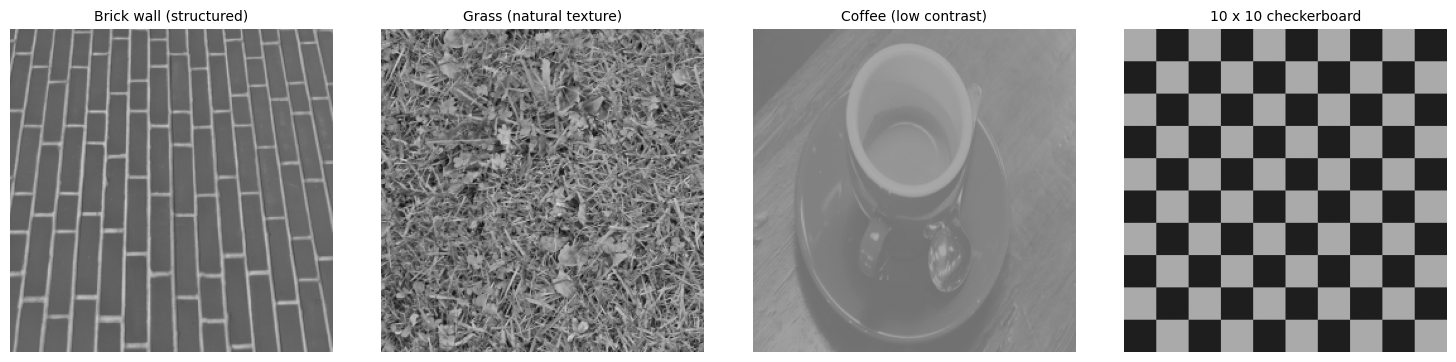

In [3]:
# Three offline scikit-image samples replace the oversized embedded Base85 arrays.
# skimage.data provides source imagery only; filtering, gradients, and Harris remain custom NumPy.
from skimage import data, __version__ as skimage_version

IMAGE_SIZE = (256, 256)  # cv2.resize expects (width, height)

def prepare_image(image, low_contrast=False):
    """Produce a local, grayscale uint8 experimental image at the common image size."""
    image = np.asarray(image)
    if image.ndim == 3:
        if image.shape[2] == 3:
            image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
        elif image.shape[2] == 4:
            image = cv2.cvtColor(image, cv2.COLOR_RGBA2GRAY)
        else:
            raise ValueError(f"Unsupported color image shape: {image.shape}")
    elif image.ndim != 2:
        raise ValueError(f"Expected 2D grayscale or RGB/RGBA image: {image.shape}")
    image = cv2.resize(image, IMAGE_SIZE, interpolation=cv2.INTER_AREA)
    if low_contrast:
        # Intentional low-contrast test condition; clip before conversion to uint8.
        image = np.clip(np.rint(112 + 0.23 * image.astype(float)), 0, 255)
    return np.asarray(image, dtype=np.uint8)

IMAGES = {
    'structured': prepare_image(data.brick()),
    'natural': prepare_image(data.grass()),
    'low_contrast': prepare_image(data.coffee(), low_contrast=True),
    'checkerboard': make_checkerboard(),
}
GT = checkerboard_ground_truth()
check_ground_truth(IMAGES['checkerboard'])
assert len(GT) == 81
PHOTOS = ('structured', 'natural', 'low_contrast')
LABELS = {
    'structured': 'Brick wall (structured)',
    'natural': 'Grass (natural texture)',
    'low_contrast': 'Coffee (low contrast)',
    'checkerboard': '10 x 10 checkerboard',
}
IMAGE_SOURCES = {
    'structured': 'scikit-image skimage.data.brick',
    'natural': 'scikit-image skimage.data.grass',
    'low_contrast': 'scikit-image skimage.data.coffee (contrast reduced for this experiment)',
    'checkerboard': 'synthetic, using the instructor checkerboard specification',
}
print(f'scikit-image {skimage_version}; sample imagery is installed locally (no image downloads).')
print('Image statistics:')
for name, image in IMAGES.items():
    print(f'{name:15} | Shape: {image.shape} | Range: [{image.min()}, {image.max()}] | Std: {image.std():.2f}')
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (name, image) in zip(axes, IMAGES.items()):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(LABELS[name], fontsize=10)
    ax.axis('off')
finish_figure(fig, 'task2_harris', 'dataset_overview.png')


## 1 · Filtering foundations (3 marks)

**Correlation** sums weighted samples without flipping a kernel; **convolution** flips it on both axes. Both use zero or reflect padding. A separable Gaussian with radius \(r=\lceil 3\sigma\rceil\) retains almost all of the Gaussian's mass; its \((2r+1)^2\) taps can be reduced to two \((2r+1)\)-tap passes. The Sobel kernels are divided by 8 so a unit-slope ramp has derivative 1.

In [4]:
# Shared NumPy filtering library; single copy used by all five tasks
PADDINGS = ("zero", "reflect")

def _as_image(img):
    img = np.asarray(img)
    if img.ndim != 2:
        raise ValueError(f"expected a 2-D grayscale array, got shape {img.shape}")
    return img.astype(np.float64, copy=False)

def _as_kernel(kernel):
    k = np.asarray(kernel, dtype=np.float64)
    if k.ndim != 2:
        raise ValueError(f"kernel must be 2-D, got shape {k.shape}")
    if k.shape[0] % 2 == 0 or k.shape[1] % 2 == 0:
        raise ValueError(f"kernel dimensions must be odd, got {k.shape}")
    return k

def pad_image(img, pad_y, pad_x, padding):
    """Pads the image on all sides, either with zeros or by mirroring ('reflect')."""
    if padding not in PADDINGS:
        raise ValueError(f"padding must be one of {PADDINGS}, got {padding!r}")
    spec = ((pad_y, pad_y), (pad_x, pad_x))
    if padding == "zero":
        return np.pad(img, spec, mode="constant", constant_values=0.0)
    if min(img.shape) < 2:
        raise ValueError("reflect padding needs an image of at least 2 x 2 pixels")
    return np.pad(img, spec, mode="reflect")

def correlate2d(img, kernel, padding="reflect"):
    """2D correlation. The output has the same size as the input, kernel sizes must be odd."""
    img, kernel = _as_image(img), _as_kernel(kernel)
    H, W = img.shape
    kh, kw = kernel.shape
    ry, rx = kh // 2, kw // 2
    padded = pad_image(img, ry, rx, padding)   # pad so the output keeps the input size
    out = np.zeros((H, W), dtype=np.float64)
    for u in range(kh):                      # loop over the kernel taps only, never over pixels
        for v in range(kw):
            w = kernel[u, v]
            if w != 0.0:                     # a zero tap adds nothing, so skip it
                out += w * padded[u:u + H, v:v + W]   # shift the image by (u, v), scale by the tap, add up
    return out

def convolve2d(img, kernel, padding="reflect"):
    """Convolution = correlation with the kernel flipped in both directions."""
    return correlate2d(img, _as_kernel(kernel)[::-1, ::-1], padding)

def separable_correlate(img, k_row, k_col, padding="reflect"):
    """Same as correlating with outer(k_col, k_row), but as two 1D passes: along the rows with k_row, then along the columns with k_col."""
    k_row = np.asarray(k_row, dtype=np.float64).reshape(1, -1)
    k_col = np.asarray(k_col, dtype=np.float64).reshape(-1, 1)
    return correlate2d(correlate2d(img, k_row, padding), k_col, padding)

def gaussian_kernel_1d(sigma, size=None, truncate=3.0):
    """1D Gaussian weights, normalised so they sum to 1.
    If size is not given: radius = ceil(truncate*sigma) and size = 2*radius + 1."""
    if sigma <= 0:
        raise ValueError("sigma must be > 0")
    if size is None:
        radius = int(math.ceil(truncate * sigma - 1e-9))     # tiny epsilon so ceil() doesn't round up by accident
        size = 2 * max(radius, 1) + 1
    if size % 2 == 0 or size < 1:
        raise ValueError("Gaussian kernel size must be a positive odd integer")
    r = size // 2
    x = np.arange(-r, r + 1, dtype=np.float64)
    g = np.exp(-(x ** 2) / (2.0 * sigma ** 2))   # sample the Gaussian
    return g / g.sum()                           # normalise so flat areas keep their brightness

def gaussian_kernel_2d(sigma, size=None, truncate=3.0):
    """2D Gaussian = outer product of the 1D Gaussian with itself."""
    g = gaussian_kernel_1d(sigma, size, truncate)
    return np.outer(g, g)

def gaussian_tail_mass(sigma, radius):
    """How much of the 1D Gaussian lies outside |x| <= radius (compared with a very wide kernel)."""
    ref_k = gaussian_kernel_1d(sigma, size=2 * int(math.ceil(12 * sigma)) + 1)
    c = ref_k.size // 2
    return float(1.0 - ref_k[c - radius:c + radius + 1].sum())

def gaussian_filter_2d(img, sigma, size=None, padding="reflect", truncate=3.0):
    """Gaussian blur with the full 2D kernel (K*K multiplications per pixel)."""
    return correlate2d(img, gaussian_kernel_2d(sigma, size, truncate), padding)

def gaussian_filter_separable(img, sigma, size=None, padding="reflect", truncate=3.0):
    """Gaussian blur as two 1D passes (2*K multiplications per pixel)."""
    g = gaussian_kernel_1d(sigma, size, truncate)
    return separable_correlate(img, g, g, padding)

def central_difference_kernels():
    """Central difference kernels: Ix = (I[x+1] - I[x-1]) / 2, same for Iy. Shapes (1,3) and (3,1).
    On a ramp with slope 1 the result is exactly 1."""
    kx = np.array([[-0.5, 0.0, 0.5]])
    return kx, kx.T.copy()

def sobel_kernels(normalize=True):
    """3x3 Sobel kernels (for correlation): kx = [1,2,1]^T times [-1,0,1], ky = kx transposed.
    With normalize=True they are divided by 8, so the result is the real derivative in grey levels per pixel."""
    kx = np.outer([1.0, 2.0, 1.0], [-1.0, 0.0, 1.0])
    if normalize:
        kx = kx / 8.0
    return kx, kx.T.copy()

def kernel_singular_values(kernel):
    """Singular values of the kernel. Only one non-zero value means rank 1, so the kernel is separable."""
    return np.linalg.svd(_as_kernel(kernel), compute_uv=False)

In [5]:
# Numerical properties and reference verification (cv2.filter2D ONLY in this verification cell).
toy = RNG.uniform(0,255,(49,53))
rows=[]
for mode, cv_border in [('zero',cv2.BORDER_CONSTANT),('reflect',cv2.BORDER_REFLECT_101)]:
    for shape in [(3,3),(5,7),(9,9)]:
        ker=RNG.normal(size=shape)
        ours=correlate2d(toy,ker,mode)
        ref=cv2.filter2D(toy,-1,ker,borderType=cv_border)
        error=float(np.max(np.abs(ours-ref)))
        rows.append((mode,str(shape),error))
        assert np.allclose(ours,ref,atol=1e-9)
        assert np.allclose(convolve2d(toy,ker,mode),correlate2d(toy,ker[::-1,::-1],mode))

assert np.allclose(gaussian_kernel_2d(1.5).sum(),1.0)
assert gaussian_kernel_2d(1.5).shape==(11,11)
for sigma in (0.8,1.5,3):
    a=gaussian_filter_2d(toy,sigma)
    b=gaussian_filter_separable(toy,sigma)
    assert np.max(np.abs(a-b)) < 1e-9
kx,ky=central_difference_kernels();sx,sy=sobel_kernels()
ramp=np.tile(np.arange(61,dtype=float),(51,1))
assert np.allclose(correlate2d(ramp,kx)[2:-2,2:-2],1.0)
assert np.allclose(correlate2d(ramp,sx)[2:-2,2:-2],1.0)
print('Maximum correlation discrepancy against OpenCV per mode/kernel:')
for row in rows: print(' ',row[0],row[1],f'{row[2]:.2e}')
print('Largest reference discrepancy:',f'{max(x[2] for x in rows):.3g}', 'grayscale levels')
print('Gaussian 11×11 kernel and its two-pass version agree: PASS')

Maximum correlation discrepancy against OpenCV per mode/kernel:
  zero (3, 3) 0.00e+00
  zero (5, 7) 0.00e+00
  zero (9, 9) 2.16e-12
  reflect (3, 3) 0.00e+00
  reflect (5, 7) 0.00e+00
  reflect (9, 9) 2.73e-12
Largest reference discrepancy: 2.73e-12 grayscale levels
Gaussian 11×11 kernel and its two-pass version agree: PASS


Kernel | full 2D ms | separable ms | measured speed-up | theoretical K/2
     3        0.60          0.34               1.78              1.5
     5        1.27          0.54               2.35              2.5
     9        3.49          0.78               4.50              4.5
    15       10.02          1.29               7.78              7.5
    21       19.34          1.75              11.02             10.5


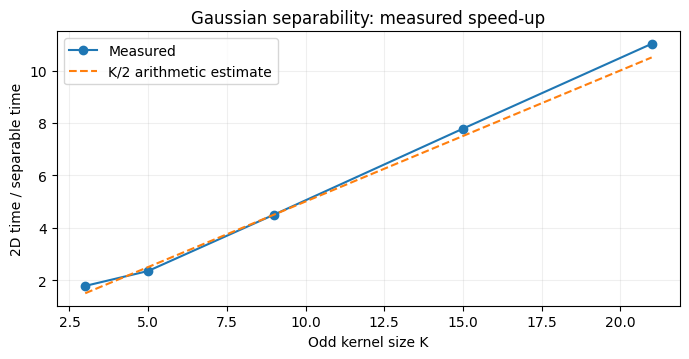

In [6]:
# Benchmark 2D versus separable Gaussian on the SAME generated image (new timings).
benchmark_image=RNG.uniform(0,255,(256,256))
bench=[]
def run_ms(f, repeats=4):
    samples=[]
    for _ in range(repeats):
        t0=time.perf_counter(); f(); samples.append((time.perf_counter()-t0)*1000)
    return float(np.median(samples))
for size in (3,5,9,15,21):
    sigma=(size-1)/6.0
    t2=run_ms(lambda:gaussian_filter_2d(benchmark_image,sigma,size=size),3)
    ts=run_ms(lambda:gaussian_filter_separable(benchmark_image,sigma,size=size),3)
    bench.append(dict(kernel_size=size,full_ms=round(t2,3),separable_ms=round(ts,3),
                      speedup=round(t2/ts,2),theoretical_speedup=size/2))
print('Kernel | full 2D ms | separable ms | measured speed-up | theoretical K/2')
for b in bench:print(f'{b["kernel_size"]:6d} {b["full_ms"]:11.2f} {b["separable_ms"]:13.2f} {b["speedup"]:18.2f} {b["theoretical_speedup"]:16.1f}')
save_rows(OUT/'task1_filtering'/'benchmark.csv',bench)
fig,ax=plt.subplots(figsize=(7,3.7));ax.plot([v['kernel_size'] for v in bench],[v['speedup'] for v in bench],'o-',label='Measured')
ax.plot([v['kernel_size'] for v in bench],[v['theoretical_speedup'] for v in bench],'--',label='K/2 arithmetic estimate')
ax.set(xlabel='Odd kernel size K',ylabel='2D time / separable time',title='Gaussian separability: measured speed-up');ax.legend();ax.grid(alpha=.2)
finish_figure(fig,'task1_filtering','separability_speedup.png')

**Interpretation.** The near-zero discrepancy verifies the choice of kernel orientation and padding (OpenCV `BORDER_REFLECT_101` matches NumPy `reflect`). The measured speed-up need not equal \(K/2\) exactly because NumPy allocation, memory traffic and fixed overhead affect timing; the operation count predicts the trend.

## 2 · Harris detector from NumPy (5 marks)

Gradients \(I_x,I_y\) form \(I_x^2,I_y^2,I_xI_y\). The Gaussian-weighted **structure tensor** is
\[
M=\begin{bmatrix}S_{xx}&S_{xy}\\S_{xy}&S_{yy}\end{bmatrix},\qquad
R=\det M-k(\operatorname{tr} M)^2.
\]
Relative threshold \(R>0.01\max(R)\), then **fully vectorized** 3 × 3 non-maximum suppression (NMS); on equal-valued plateaus, a stable raster-order tie rule retains one representative pixel. A border of \(\lceil3\sigma\rceil+1\) pixels is excluded.

In [7]:
# One shared NumPy Harris pipeline
from numpy.lib.stride_tricks import sliding_window_view

def compute_gradients(img, operator="sobel", padding="reflect"):
    """Ix and Iy in grey levels per pixel (x = columns, y = rows, y points down)."""
    img = _as_image(img)
    if operator == "sobel":
        kx, ky = sobel_kernels()                    # divided by 8, so a ramp with slope 1 gives 1
    elif operator == "central":
        kx, ky = central_difference_kernels()
    else:
        raise ValueError(f"operator must be 'sobel' or 'central', got {operator!r}")
    return correlate2d(img, kx, padding), correlate2d(img, ky, padding)

def structure_tensor(Ix, Iy, sigma, padding="reflect"):
    """Entries of M at every pixel: M = [[Sxx, Sxy], [Sxy, Syy]].
    Each one is a Gaussian-weighted sum of Ix*Ix, Iy*Iy or Ix*Iy over the window around the pixel."""
    Sxx = gaussian_filter_separable(Ix * Ix, sigma, padding=padding)
    Syy = gaussian_filter_separable(Iy * Iy, sigma, padding=padding)
    Sxy = gaussian_filter_separable(Ix * Iy, sigma, padding=padding)
    return Sxx, Syy, Sxy

def harris_response(Sxx, Syy, Sxy, k=0.04):
    """R = det(M) - k * trace(M)^2 at every pixel. Also returns det and trace."""
    det = Sxx * Syy - Sxy ** 2
    trace = Sxx + Syy
    return det - k * trace ** 2, det, trace

def relative_threshold(R, rel):
    """rel * max(R). If R is never positive there can be no corner, so the threshold is infinite."""
    r_max = float(R.max())
    return rel * r_max if r_max > 0 else np.inf

def non_max_suppression_3x3(R, thr):
    """Boolean mask: R > thr and the pixel is a local maximum of its 3x3 neighbourhood. No loops.
    Ties: on a plateau of equal values only the first pixel in raster order survives
    (strictly greater than the neighbours before it, greater or equal to the ones after it).
    Without this a checkerboard corner would give 4 detections, because its 4 pixels have the same R."""
    H, W = R.shape
    padded = np.pad(R, 1, mode="constant", constant_values=-np.inf)
    nb = sliding_window_view(padded, (3, 3)).reshape(H, W, 9)   # 9 neighbours in raster order, index 4 is the pixel itself
    before = nb[..., :4].max(axis=-1)       # up-left, up, up-right, left
    after = nb[..., 5:].max(axis=-1)        # right, down-left, down, down-right
    return (R > thr) & (R > before) & (R >= after)

def classify_pixels_by_R(R, rel):
    """0 = flat, 1 = edge, 2 = corner, using tau = rel * max(R):
    corner if R > tau, edge if R < -tau, flat if |R| <= tau. (A rough picture. Task 3 does it with eigenvalues.)"""
    tau = rel * max(float(R.max()), 0.0)
    labels = np.zeros(R.shape, dtype=np.int8)
    labels[R < -tau] = 1
    labels[R > tau] = 2
    return labels

def detect_harris(img, sigma=1.5, k=0.04, rel_thr=0.01, operator="sobel", padding="reflect", border=None):
    """Full Harris pipeline. Returns a dict with all the intermediate images and the corners.
    border = number of pixels at the image edge where corners are ignored (default ceil(3*sigma) + 1,
    the window radius plus one for the gradient), because the window there looks at padded pixels.
    corners = array (N, 2) of (x, y) pixel positions, strongest first."""
    img = _as_image(img)
    Ix, Iy = compute_gradients(img, operator, padding)
    Sxx, Syy, Sxy = structure_tensor(Ix, Iy, sigma, padding)
    R, det, trace = harris_response(Sxx, Syy, Sxy, k)
    thr = relative_threshold(R, rel_thr)
    mask = non_max_suppression_3x3(R, thr)
    b = int(math.ceil(3 * sigma)) + 1 if border is None else int(border)
    if b > 0:
        mask[:b, :] = False
        mask[-b:, :] = False
        mask[:, :b] = False
        mask[:, -b:] = False
    ys, xs = np.nonzero(mask)
    order = np.argsort(-R[ys, xs], kind="stable")           # strongest corner first
    corners = np.stack([xs[order], ys[order]], axis=1)
    return dict(Ix=Ix, Iy=Iy, Sxx=Sxx, Syy=Syy, Sxy=Sxy, R=R, det=det, trace=trace, mask=mask,
                corners=corners, scores=R[ys[order], xs[order]], threshold=thr, border=b,
                params=dict(sigma=sigma, k=k, rel_thr=rel_thr, operator=operator, padding=padding))

In [8]:
# Validate tensor entries, NMS tie handling, and checkerboard localization.
test=detect_harris(IMAGES['checkerboard'],sigma=SIGMA,k=K)
assert test['R'].shape==IMAGES['checkerboard'].shape
assert np.min(test['det']) > -1e-6
assert np.allclose(test['det'],test['Sxx']*test['Syy']-test['Sxy']**2)
assert len(test['corners'])==81, f'Checkerboard should produce 81 points, got {len(test["corners"])}'
d_gt=np.hypot(test['corners'][:,None,0]-GT[None,:,0],test['corners'][:,None,1]-GT[None,:,1])
assert np.all(np.min(d_gt,axis=0)<1.01)
plateau=np.zeros((15,15));plateau[4:7,4:7]=10
assert np.count_nonzero(non_max_suppression_3x3(plateau,1))==1
print('81/81 checkerboard true corners recovered within 1 px; mean error:',round(float(d_gt.min(axis=0).mean()),3),'px')
print('Vectorized 3×3 NMS plateau tie-break: PASS')
DETECTIONS={key:detect_harris(img,SIGMA,K,REL_THR) for key,img in IMAGES.items()}
for key,d in DETECTIONS.items():print(f'{key:13} {len(d["corners"]):5} corners; max R={d["R"].max():.3g}')

81/81 checkerboard true corners recovered within 1 px; mean error: 0.707 px
Vectorized 3×3 NMS plateau tie-break: PASS
structured      165 corners; max R=1.96e+05
natural         852 corners; max R=1.07e+06
low_contrast     60 corners; max R=6.82e+03
checkerboard     81 corners; max R=1.9e+06


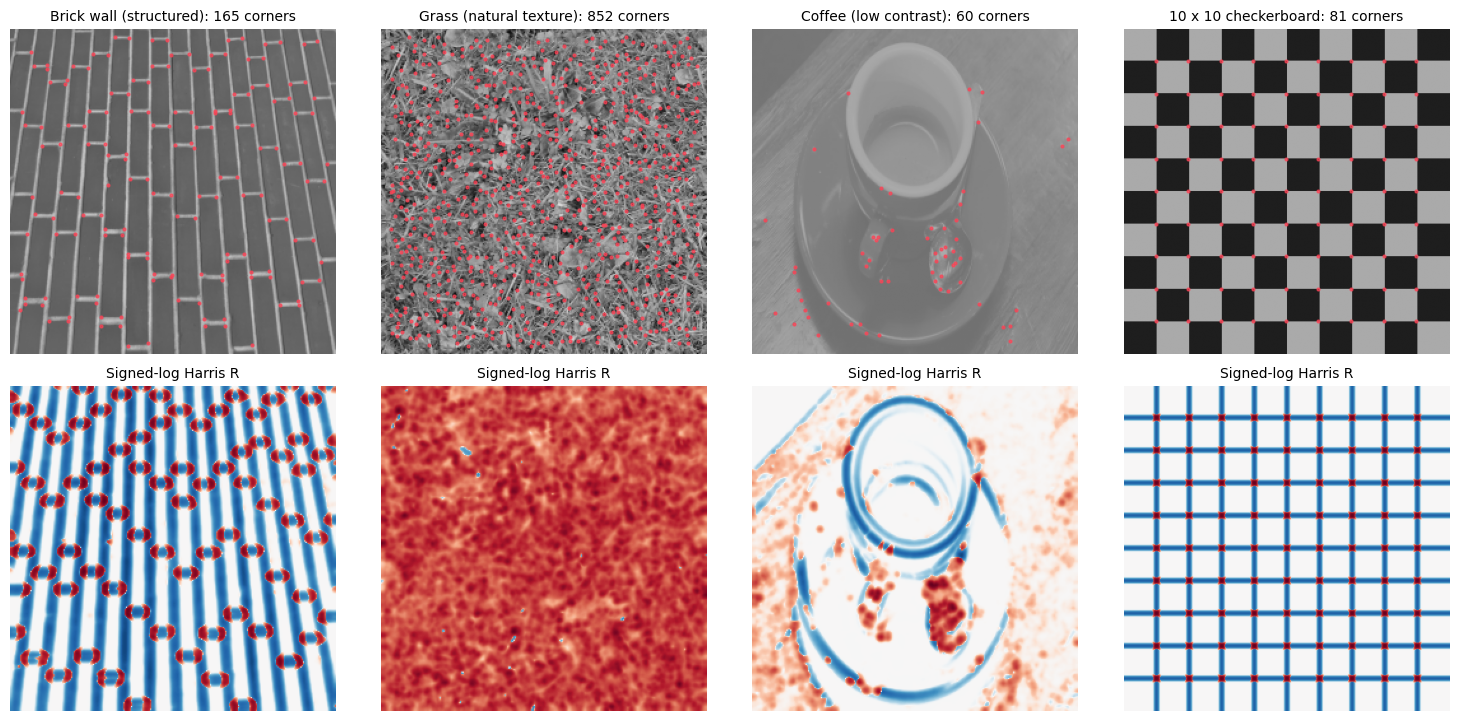

In [9]:
fig,axes=plt.subplots(2,4,figsize=(15,7.3))
from matplotlib.colors import SymLogNorm
for j,(key,img) in enumerate(IMAGES.items()):
    d=DETECTIONS[key]
    axes[0,j].imshow(img,cmap='gray',vmin=0,vmax=255)
    if len(d['corners']):axes[0,j].scatter(d['corners'][:,0],d['corners'][:,1],s=4,c='#ff4154',alpha=.7)
    axes[0,j].set_title(f'{LABELS[key]}: {len(d["corners"])} corners',fontsize=10)
    r=d['R'];lin=max(float(np.max(np.abs(r)))*.0002,1e-6)
    axes[1,j].imshow(r,cmap='RdBu_r',norm=SymLogNorm(linthresh=lin,vmin=-max(np.abs(r).max(),1),vmax=max(np.abs(r).max(),1)))
    axes[1,j].set_title('Signed-log Harris R',fontsize=10)
    for i in range(2):axes[i,j].axis('off')
finish_figure(fig,'task2_harris','corner_overlays_and_heatmaps.png')

In [10]:
# Select representative locations on the checkerboard for a corner, straight edge and flat area.
board=DETECTIONS['checkerboard']
locations={'corner':(39,39),'edge':(39,20),'flat':(20,20)}
print('Region | Sxx | Syy | Sxy | R | classification')
for label,(x,y) in locations.items():
    r=float(board['R'][y,x]);classification='corner' if r>board['threshold'] else ('edge' if r<-board['threshold'] else 'flat')
    print(f'{label:6} {board["Sxx"][y,x]:10.2f} {board["Syy"][y,x]:10.2f} {board["Sxy"][y,x]:10.2f} {r:12.2f} {classification}')

Region | Sxx | Syy | Sxy | R | classification
corner    1503.93    1503.93       3.44   1899900.02 corner
edge      2347.18       0.00       0.00   -220371.02 edge
flat         0.00       0.00       0.00         0.00 flat


**Why the three responses differ.** A corner changes intensity in two independent directions, yielding two substantial eigenvalues, large determinant, and often \(R>0\). An edge mainly changes in one direction: determinant ≈ 0, so \(R<0\). A locally flat region has negligible gradients and \(R\approx0\). Heatmaps show both positive and negative response, while the overlay visualizes thresholded NMS peaks.

## 3 · Closed-form eigenvalues and response geometry (3 marks)

For \(M=\left[\begin{smallmatrix}a&b\\b&c\end{smallmatrix}\right]\),
\[\lambda_{1,2}=\frac{a+c}{2}\pm\sqrt{\left(\frac{a-c}{2}\right)^2+b^2},\quad \lambda_1\ge\lambda_2\ge0.\]
Since \(\det M=\lambda_1\lambda_2\) and \(\operatorname{tr}M=\lambda_1+\lambda_2\),
\[R=\lambda_1\lambda_2-k(\lambda_1+\lambda_2)^2
=\lambda_1^2[r-k(1+r)^2],\quad r=\lambda_2/\lambda_1.\]
For \(\lambda_1>0\), \(0<k<1/4\), and **positive response without an amplitude threshold**, the corner region is \(r>r_{\min}=\frac{2k}{1-2k+\sqrt{1-4k}}\). A positive detection threshold additionally requires enough gradient *magnitude*.

In [11]:
def tensor_eigenvalues(Sxx,Syy,Sxy):
    half=.5*(Sxx+Syy)
    radius=np.hypot(.5*(Sxx-Syy),Sxy)
    return half+radius, np.maximum(half-radius,0.0)

def ratio_boundary(k):
    if not 0<k<.25: raise ValueError('Requires 0 < k < 0.25')
    return 2*k/(1-2*k+np.sqrt(1-4*k))

for k0 in (.04,.06):
    r=float(ratio_boundary(k0))
    print(f'k={k0:.2f}: min lambda2/lambda1 = {r:.6f}; max lambda1/lambda2 = {1/r:.3f}')

print('Numeric determinant / trace / R relative errors:')
EIG={}
for key,d in DETECTIONS.items():
    l1,l2=tensor_eigenvalues(d['Sxx'],d['Syy'],d['Sxy']);EIG[key]=(l1,l2)
    scale=max(float(np.max(l1**2)),1.0)
    e_det=float(np.max(np.abs(d['det']-l1*l2))/scale)
    e_trace=float(np.max(np.abs(d['trace']-(l1+l2)))/max(float(l1.max()),1.0))
    e_r=float(np.max(np.abs(d['R']-(l1*l2-K*(l1+l2)**2)))/scale)
    assert max(e_det,e_trace,e_r)<2e-10
    # R > 0 and r > r_min must agree outside tiny floating-point regions.
    sign_from_eig=(l2>ratio_boundary(K)*l1)&(l1>1e-8)
    mismatch=int(np.count_nonzero((d['R']>1e-7*scale) & ~sign_from_eig))
    assert mismatch==0
    print(f' {key:13}: det={e_det:.2e} trace={e_trace:.2e} R={e_r:.2e}')

k=0.04: min lambda2/lambda1 = 0.043561; max lambda1/lambda2 = 22.956
k=0.06: min lambda2/lambda1 = 0.068502; max lambda1/lambda2 = 14.598
Numeric determinant / trace / R relative errors:
 structured   : det=1.01e-16 trace=1.63e-16 R=1.13e-16
 natural      : det=6.70e-17 trace=1.99e-16 R=6.70e-17
 low_contrast : det=1.15e-16 trace=1.89e-16 R=1.15e-16
 checkerboard : det=6.34e-17 trace=1.94e-16 R=8.45e-17


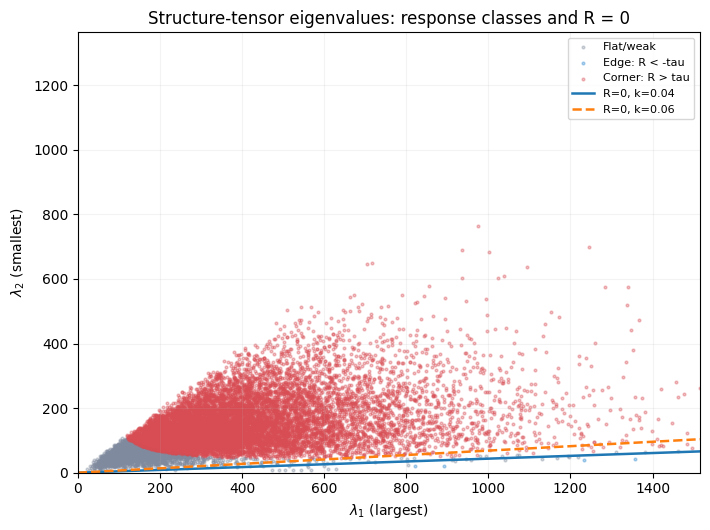

In [12]:
# Eigenvalue scatter for the natural image; colors are Harris RESPONSE classes (pre-NMS).
name='natural';d=DETECTIONS[name];l1,l2=EIG[name]
tau=d['threshold'];classes=classify_pixels_by_R(d['R'],REL_THR)
flatind=l1.ravel(); small=l2.ravel(); colors=classes.ravel()
ix=RNG.choice(flatind.size,size=min(13500,flatind.size),replace=False)
fig,ax=plt.subplots(figsize=(7.2,5.4))
for code,color,caption in ((0,'#7f8a9e','Flat/weak'),(1,'#2483cd','Edge: R < -tau'),(2,'#d84c53','Corner: R > tau')):
    subset=ix[colors[ix]==code]
    ax.scatter(flatind[subset],small[subset],s=4,alpha=.35,color=color,label=caption)
mx=float(np.quantile(flatind[ix],.998));x=np.linspace(0,mx,350)
for kval,style in ((.04,'-'),(.06,'--')):
    ax.plot(x,ratio_boundary(kval)*x,style,lw=1.8,label=f'R=0, k={kval:.2f}')
ax.set(xlim=(0,mx),ylim=(0,mx*.9),xlabel=r'$\lambda_1$ (largest)',ylabel=r'$\lambda_2$ (smallest)',
       title='Structure-tensor eigenvalues: response classes and R = 0')
ax.grid(alpha=.15);ax.legend(fontsize=8)
finish_figure(fig,'task3_eigenvalues','eigenvalue_regions.png')

**Interpretation.** Near the origin both eigenvalues are weak (flat/low texture); close to the horizontal axis only one is appreciable (edge-like); above the \(R=0\) line both directions contribute (corner-like). The two boundaries illustrate why increasing \(k\) requires a more balanced pair of eigenvalues. Actual selected corners also need to clear the positive response threshold and NMS.

## 4 · Geometric and photometric repeatability (5 marks)

For a reference corner \(p\in A\), transform its coordinates to \(T(p)\), discard positions outside the **valid interior of B**, and count it as reproduced if **any** corner detected in \(B\) lies within **2 pixels**. Thus
\[\mathrm{repeatability}=\frac{\#\{p\in C_A\cap T^{-1}(\Omega_B):\min_{q\in C_B}\|T(p)-q\|_2\le2\}}{\#\{p\in C_A\cap T^{-1}(\Omega_B)\}}.\]
All detector settings remain fixed at \(\sigma=1.5,k=0.04,\tau_{\mathrm{rel}}=0.01\). The **relative** threshold uses the same fraction (1%) of the strongest valid response in each transformed image; the **fixed absolute** comparison uses the threshold calibrated once on A. Rotation uses an expanded canvas and the **actual forward affine map**; OpenCV's half-pixel center mapping is used for resizing. The geometry excludes transform padding, border neighborhoods and out-of-frame reference corners. Repetitions of noise use independent seeded trials.

In [13]:
def allowed_region(shape,border,valid=None):
    ok=np.zeros(shape,dtype=bool)
    if min(shape)<=2*border:return ok
    ok[border:-border,border:-border]=True
    if valid is not None:
        # Erode by filter + NMS radius to avoid contamination from the rotation's black padding.
        bad=np.pad(~valid,border,constant_values=False).astype(np.int64)
        integral=np.pad(bad.cumsum(axis=0).cumsum(axis=1),((1,0),(1,0)))
        n=2*border+1;h,w=shape
        region_bad=integral[n:n+h,n:n+w]-integral[:h,n:n+w]-integral[n:n+h,:w]+integral[:h,:w]
        ok &= region_bad==0
    return ok

def response_map(img,sigma=SIGMA,k=K,window='gaussian'):
    Ix,Iy=compute_gradients(img,GRADIENT,PADDING)
    if window=='gaussian':
        Sxx,Syy,Sxy=structure_tensor(Ix,Iy,sigma,PADDING)
    elif window=='box':
        sz=len(gaussian_kernel_1d(sigma));v=np.ones(sz,dtype=float)/sz
        Sxx=separable_correlate(Ix*Ix,v,v,PADDING)
        Syy=separable_correlate(Iy*Iy,v,v,PADDING)
        Sxy=separable_correlate(Ix*Iy,v,v,PADDING)
    else:raise ValueError(window)
    return harris_response(Sxx,Syy,Sxy,k)[0]

def detect_from_map(R,allow,threshold):
    return non_max_suppression_3x3(R,threshold)&allow

def coords(mask):
    yy,xx=np.nonzero(mask)
    return np.column_stack((xx,yy)).astype(float)

def repeatability(mapped,allowed,detected_mask,tol=2):
    # Evaluate a 7x7 offset neighborhood to safely cover radius 2 around subpixel coordinates.
    x=np.rint(mapped[:,0]).astype(int);y=np.rint(mapped[:,1]).astype(int)
    h,w=allowed.shape
    inside=(x>=0)&(y>=0)&(x<w)&(y<h)
    eligible=np.zeros(len(x),dtype=bool)
    eligible[inside]=allowed[y[inside],x[inside]]
    pts=mapped[eligible]
    if not len(pts):return np.nan,0,0
    # A centered 7×7 covers every integer target within 2 px from subpixel coordinates.
    px=np.rint(pts[:,0]).astype(int);py=np.rint(pts[:,1]).astype(int)
    matched=np.zeros(len(pts),dtype=bool)
    for dy in range(-3,4):
        for dx in range(-3,4):
            xx=px+dx;yy=py+dy
            safe=(xx>=0)&(yy>=0)&(xx<w)&(yy<h)&(np.hypot(xx-pts[:,0],yy-pts[:,1])<=tol)
            # advanced indexing after clamping is valid for vectorization.
            matched|=safe & detected_mask[np.clip(yy,0,h-1),np.clip(xx,0,w-1)]
    return float(np.mean(matched)),int(len(pts)),int(matched.sum())

def reference_record(img):
    R=response_map(img);border=math.ceil(3*SIGMA)+1
    allow=allowed_region(R.shape,border)
    threshold=REL_THR*max(float(R[allow].max()),0)
    corners=coords(detect_from_map(R,allow,threshold))
    return dict(img=img,R=R,threshold=threshold,corners=corners)

REFERENCES={key:reference_record(IMAGES[key]) for key in PHOTOS}

def rotate(img,angle):
    h,w=img.shape;t=np.deg2rad(angle);c,s=np.cos(t),np.sin(t)
    ww=int(np.ceil(w*abs(c)+h*abs(s)-1e-9));hh=int(np.ceil(w*abs(s)+h*abs(c)-1e-9))
    lin=np.array([[c,s],[-s,c]])
    cen=np.array([(w-1)/2,(h-1)/2]);ncen=np.array([(ww-1)/2,(hh-1)/2])
    mat=np.column_stack((lin,ncen-lin@cen))
    transformed=cv2.warpAffine(np.asarray(img,dtype=np.float32),mat,(ww,hh),flags=cv2.INTER_LINEAR)
    coverage=cv2.warpAffine(np.ones_like(img,dtype=np.float32),mat,(ww,hh),flags=cv2.INTER_LINEAR)>0.999
    return transformed.astype(float),lambda pts:pts@lin.T+mat[:,2],coverage

def scale(img,s):
    h,w=img.shape;hh=max(1,int(round(h*s)));ww=max(1,int(round(w*s)))
    transformed=cv2.resize(np.asarray(img,dtype=np.float32),(ww,hh),interpolation=cv2.INTER_LINEAR)
    sx,sy=ww/w,hh/h
    return transformed.astype(float),lambda pts:(pts+.5)*np.array([sx,sy])-.5,None

def photometric(img,kind,value,ideal=False,seed=None):
    a=np.asarray(img,dtype=float)
    if kind=='brightness':out=a+value
    elif kind=='contrast':out=a*value
    elif kind=='noise':out=a+np.random.default_rng(seed).normal(0,value,a.shape)
    else:raise ValueError(kind)
    return out if ideal else np.clip(np.rint(out),0,255).astype(np.uint8)

def measure_case(key,kind,value,ideal=False,seed=0):
    ref=REFERENCES[key]
    if kind=='rotation':b,transform,coverage=rotate(ref['img'],value)
    elif kind=='scaling':b,transform,coverage=scale(ref['img'],value)
    else:
        b=photometric(ref['img'],kind,value,ideal,seed)
        transform=lambda pts:pts
        coverage=None
    r=response_map(b)
    allow=allowed_region(r.shape,math.ceil(3*SIGMA)+1,coverage)
    if not np.any(allow):return dict(relative=np.nan,fixed=np.nan,eligible=0,detected_relative=0,detected_fixed=0)
    mapped=transform(ref['corners'])
    out={'eligible':None}
    for mode,thr in (('relative',REL_THR*max(float(r[allow].max()),0)),('fixed',ref['threshold'])):
        mask=detect_from_map(r,allow,thr)
        score,n,matched=repeatability(mapped,allow,mask)
        out[mode]=score;out['eligible']=n;out['detected_'+mode]=int(mask.sum())
    return out

In [14]:
# Geometric mapping unit checks: identity and 90° mapping are exact, half-pixel scale is explicit.
ref=REFERENCES['structured']
for angle in (0,90,180):
    b,map_points,coverage=rotate(ref['img'],angle)
    expected=map_points(ref['corners'])
    assert np.all((expected[:,0]>-1)&(expected[:,0]<b.shape[1]+1))
    assert np.all((expected[:,1]>-1)&(expected[:,1]<b.shape[0]+1))
assert abs(scale(ref['img'],.5)[1](np.array([[20.,20.]]))[0,0]-9.75)<1e-12
r=measure_case('structured','rotation',0)
assert r['relative']>0.999 and r['fixed']>0.999
print('Coordinate maps: 0/90/180-degree bounds and OpenCV resize pixel center PASS')
print('Identity repeatability (structured):',r['relative'])

Coordinate maps: 0/90/180-degree bounds and OpenCV resize pixel center PASS
Identity repeatability (structured): 1.0


In [15]:
# All required ranges, 2 px tolerance; collect actual repeatability and counts.
VALUES={'rotation':list(range(0,181,15)),
        'scaling':[.5,.65,.8,1.0,1.2,1.5,2.0],
        'brightness':[0,20,40,60,80],
        'contrast':[.5,.75,1,1.25,1.5,1.75,2],
        'noise':[0,5,10,15,20,25,30]}
RESULTS=[]
for kind,values in VALUES.items():
    for key in PHOTOS:
        for value in values:
            seeds=range(5) if kind=='noise' else range(1)
            cases=[measure_case(key,kind,value,seed=SEED+ii+103) for ii in seeds]
            # Record both thresholding strategies for every case.
            RESULTS.append(dict(experiment=kind,image=key,x=value,
                relative=float(np.nanmean([c['relative'] for c in cases])),
                fixed=float(np.nanmean([c['fixed'] for c in cases])),
                relative_std=float(np.nanstd([c['relative'] for c in cases])),
                n_eligible=int(np.mean([c['eligible'] for c in cases])),
                n_detected_rel=float(np.mean([c['detected_relative'] for c in cases])),
                trials=len(cases)))
assert len(RESULTS)==len(PHOTOS)*sum(map(len,VALUES.values()))
save_rows(OUT/'task4_invariance'/'repeatability.csv',RESULTS)
print(f'Completed {len(RESULTS)} parameter/image settings, five independent seeds for Gaussian noise.')
for kind in VALUES:
    print(kind+':',[(key,round(next(v['relative'] for v in RESULTS if v['image']==key and v['experiment']==kind and v['x']==VALUES[kind][-1]),3)) for key in PHOTOS])

Completed 117 parameter/image settings, five independent seeds for Gaussian noise.
rotation: [('structured', 1.0), ('natural', 1.0), ('low_contrast', 1.0)]
scaling: [('structured', 0.697), ('natural', 0.757), ('low_contrast', 0.833)]
brightness: [('structured', 0.988), ('natural', 0.981), ('low_contrast', 1.0)]
contrast: [('structured', 0.812), ('natural', 0.696), ('low_contrast', 0.233)]
noise: [('structured', 0.553), ('natural', 0.576), ('low_contrast', 0.283)]


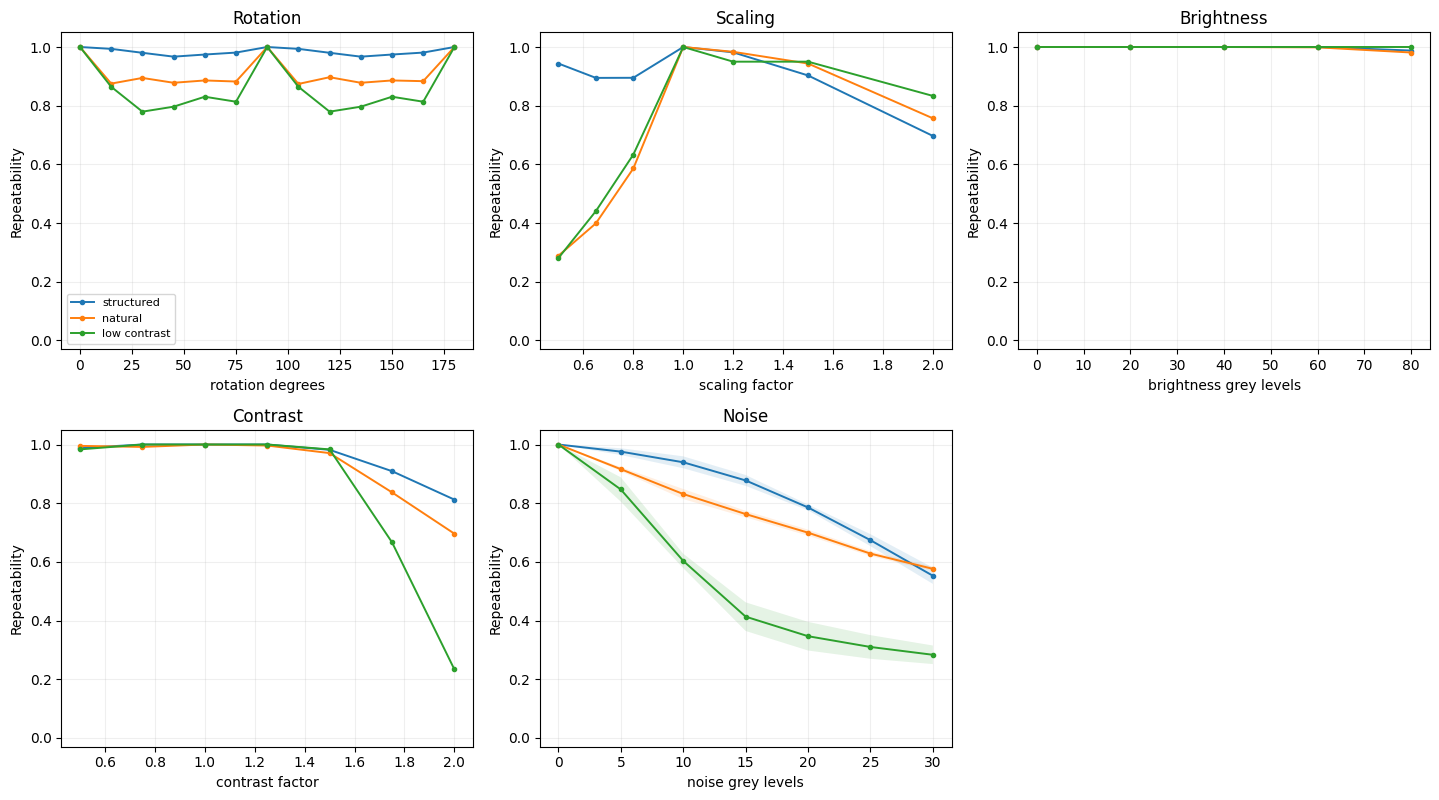

In [16]:
# Invariance curves (relative threshold on the new images).
fig,axes=plt.subplots(2,3,figsize=(14.5,8.1));ax_list=axes.ravel()
for idx,(kind,xx) in enumerate(VALUES.items()):
    ax=ax_list[idx]
    for key in PHOTOS:
        subset=[v for v in RESULTS if v['experiment']==kind and v['image']==key]
        xv=[r['x'] for r in subset];yv=[r['relative'] for r in subset];err=[r['relative_std'] for r in subset]
        ax.plot(xv,yv,'o-',ms=3,lw=1.4,label=key.replace('_',' '))
        if kind=='noise':ax.fill_between(xv,np.array(yv)-err,np.array(yv)+err,alpha=.12)
    ax.set(xlabel=kind+' '+('degrees' if kind=='rotation' else 'factor' if kind in ('scaling','contrast') else 'grey levels'),
           ylabel='Repeatability',title=kind.title(),ylim=(-.03,1.05))
    ax.grid(alpha=.2)
ax_list[0].legend(fontsize=8,loc='lower left')
ax_list[-1].axis('off')
finish_figure(fig,'task4_invariance','five_invariance_curves.png')

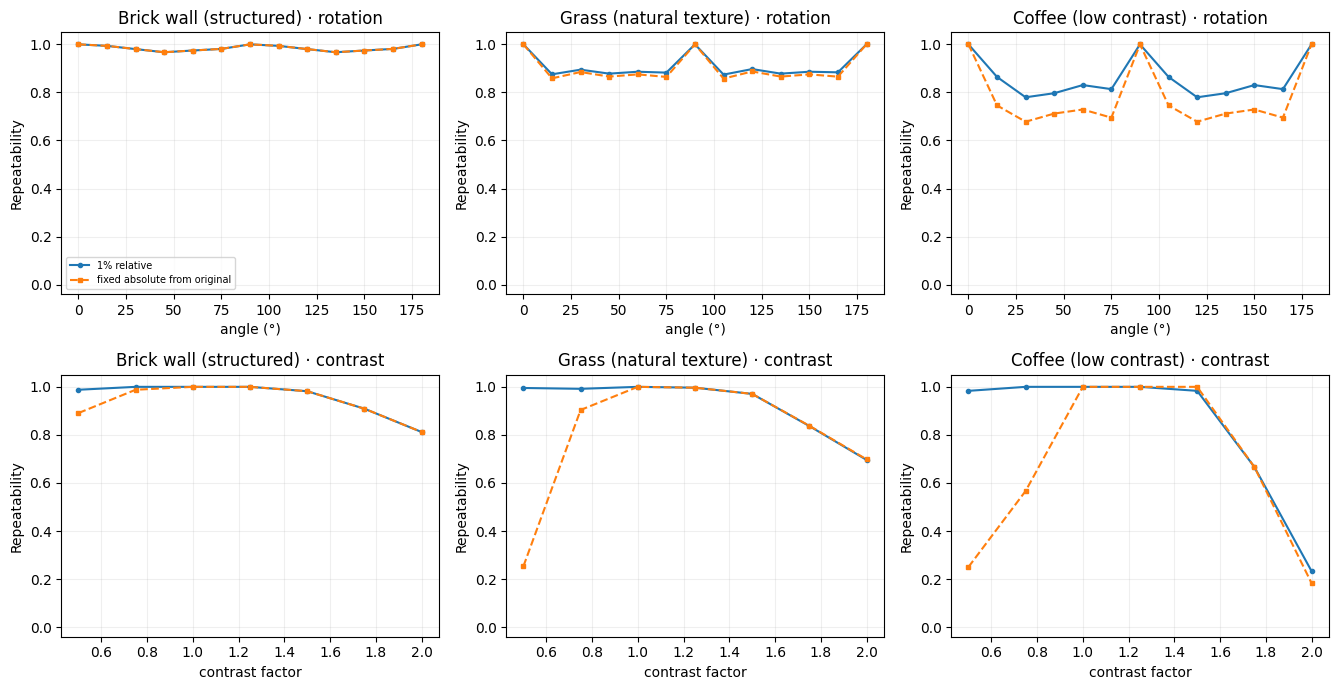

In [17]:
# Fixed versus relative threshold, explicitly requested under rotation and contrast.
fig,axes=plt.subplots(2,3,figsize=(13.5,7))
for i,kind in enumerate(('rotation','contrast')):
    for j,key in enumerate(PHOTOS):
        ax=axes[i,j];sub=[v for v in RESULTS if v['experiment']==kind and v['image']==key]
        x=[v['x'] for v in sub]
        ax.plot(x,[v['relative'] for v in sub],'-o',ms=3,label='1% relative')
        ax.plot(x,[v['fixed'] for v in sub],'--s',ms=3,label='fixed absolute from original')
        ax.set(title=f'{LABELS[key]} · {kind}',xlabel='angle (°)' if kind=='rotation' else 'contrast factor',
               ylabel='Repeatability',ylim=(-.04,1.05));ax.grid(alpha=.2)
        if i==0 and j==0:ax.legend(fontsize=7)
finish_figure(fig,'task4_invariance','relative_vs_fixed.png')

In [18]:
# Separate ideal-float vs clipped/rounded 8-bit photometric checks.
# Theory: add b -> gradients unchanged; multiply by c -> R multiplied by c^4
THEORY=[]
for key in PHOTOS:
    for kind,value in (('brightness',80),('contrast',.5),('contrast',2)):
        ideal=measure_case(key,kind,value,ideal=True)
        digit=measure_case(key,kind,value,ideal=False)
        THEORY.append(dict(image=key,kind=kind,value=value,ideal_relative=ideal['relative'],
                           eight_bit_relative=digit['relative'],ideal_fixed=ideal['fixed'],
                           eight_bit_fixed=digit['fixed']))
print('New-image theory checks:')
for row in THEORY:
    print(row['image'],row['kind'],row['value'],
          'ideal relative',f'{row["ideal_relative"]:.3f}',
          '| 8-bit relative',f'{row["eight_bit_relative"]:.3f}',
          '| ideal fixed',f'{row["ideal_fixed"]:.3f}')
save_rows(OUT/'task4_invariance'/'ideal_vs_quantized.csv',THEORY)

New-image theory checks:
structured brightness 80 ideal relative 1.000 | 8-bit relative 0.988 | ideal fixed 1.000
structured contrast 0.5 ideal relative 1.000 | 8-bit relative 0.988 | ideal fixed 0.903
structured contrast 2 ideal relative 1.000 | 8-bit relative 0.812 | ideal fixed 1.000
natural brightness 80 ideal relative 1.000 | 8-bit relative 0.981 | ideal fixed 1.000
natural contrast 0.5 ideal relative 1.000 | 8-bit relative 0.995 | ideal fixed 0.256
natural contrast 2 ideal relative 1.000 | 8-bit relative 0.696 | ideal fixed 1.000
low_contrast brightness 80 ideal relative 1.000 | 8-bit relative 1.000 | ideal fixed 1.000
low_contrast contrast 0.5 ideal relative 1.000 | 8-bit relative 0.983 | ideal fixed 0.233
low_contrast contrast 2 ideal relative 1.000 | 8-bit relative 0.233 | ideal fixed 1.000


**Expected mechanisms and limitations.**

- **Rotation:** for a continuous isotropic Gaussian model, \(M'\approx QMQ^\top\); determinant, trace, and eigenvalues are preserved. Bilinear resampling at non-right angles changes the gradients and can lower repeatability.
- **Scale:** not invariant with a pixel-fixed Sobel derivative and Gaussian window; features appear at different scales. The curves measure this effect directly.
- **Brightness:** \(\nabla(I+b)=\nabla I\), so ideal unbounded images have the same response; rounding/clipping creates deviations.
- **Contrast:** \(\nabla(cI)=c\nabla I\), \(M'=c^2M\), and \(R'=c^4R\). Relative threshold compensates for ideal scaling; a fixed absolute threshold does not. In 8-bit images saturation introduces irrecoverable changes.
- **Noise:** random gradients inflate tensor energy and may generate false positive local maxima. Averaged repeats report *retention*, not precision: extra false detections are not penalized by this metric.

**Border convention:** a reference corner is eligible only when its mapped location lies in the transformed image's valid interior. For rotations, erosion removes the black canvas and a neighborhood around it, preventing padding artifacts from being counted as natural structures.

## 5 · Parameter study and OpenCV comparison (2 marks)

Vary \(\sigma\in\{0.5,1,1.5,2,3,4\}\), \(k\in\{0.02,0.04,0.06,0.1\}\), and relative threshold \(t\in\{0.001,0.005,0.01,0.05,0.1\}\) across all three images. Report corner counts; counts show detector sensitivity, **not** localization accuracy. Compare equal-size Gaussian and box windows, and measure directed agreement within 2 px against `cv2.cornerHarris`.

In [19]:
# Response-only helper reuses the same gradients / kernels from Tasks 1-4.
def points_from_response(r,border=6,rel=.01):
    allowed=allowed_region(r.shape,border)
    thr=rel*max(float(r[allowed].max()),0)
    return coords(detect_from_map(r,allowed,thr))

def count_peaks_for_thresholds(r,border,rels):
    allowed=allowed_region(r.shape,border)
    peaks=np.sort(r[non_max_suppression_3x3(r,0)&allowed])
    maximum=max(float(r[allowed].max()),0)
    return [int(len(peaks)-np.searchsorted(peaks,rel*maximum,side='right')) for rel in rels]

SIGMAS=(.5,1.,1.5,2.,3.,4.)
KS=(.02,.04,.06,.10)
THRESHOLDS=(.001,.005,.01,.05,.10)
GRID=[]
for key in PHOTOS:
    img=IMAGES[key]
    ix,iy=compute_gradients(img)
    for sig in SIGMAS:
        xx=gaussian_filter_separable(ix*ix,sig)
        yy=gaussian_filter_separable(iy*iy,sig)
        xy=gaussian_filter_separable(ix*iy,sig)
        border=int(math.ceil(3*sig))+1
        for kval in KS:
            response=harris_response(xx,yy,xy,kval)[0]
            counts=count_peaks_for_thresholds(response,border,THRESHOLDS)
            for thr,count in zip(THRESHOLDS,counts):
                GRID.append(dict(image=key,sigma=sig,k=kval,threshold=thr,count=count))
assert len(GRID)==360
save_rows(OUT/'task5_comparison'/'parameter_grid.csv',GRID)
print('Parameter grid:',len(GRID),'combinations = 3 images × 6 sigma × 4 k × 5 thresholds')
print('Corner counts (k=0.04, relative threshold=0.01):')
print('sigma',' '.join(f'{key:>14}' for key in PHOTOS))
for sig in SIGMAS:
    print(f'{sig:4.1f}', ' '.join(f'{next(r["count"] for r in GRID if r["image"]==key and r["sigma"]==sig and r["k"]==.04 and r["threshold"]==.01):14d}' for key in PHOTOS))

Parameter grid: 360 combinations = 3 images × 6 sigma × 4 k × 5 thresholds
Corner counts (k=0.04, relative threshold=0.01):
sigma     structured        natural   low_contrast
 0.5            378           2765            102
 1.0            241           1567             66
 1.5            165            852             60
 2.0            141            516             47
 3.0            123            240             35
 4.0            116            143             29


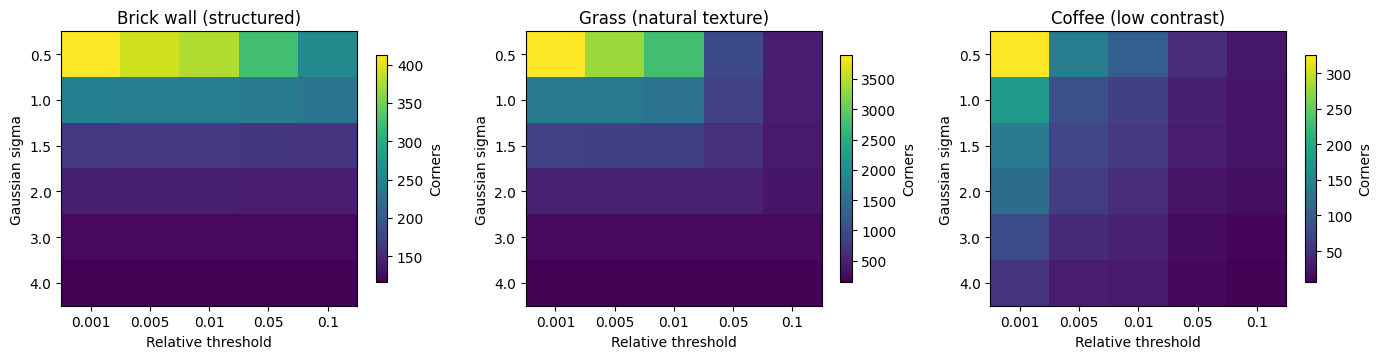

In [20]:
fig,axes=plt.subplots(1,3,figsize=(14,3.7))
for ax,key in zip(axes,PHOTOS):
    mat=np.array([[next(r['count'] for r in GRID if r['image']==key and r['sigma']==s and r['k']==.04 and r['threshold']==t)
                   for t in THRESHOLDS] for s in SIGMAS])
    im=ax.imshow(mat,cmap='viridis',aspect='auto')
    ax.set(title=LABELS[key],xlabel='Relative threshold',ylabel='Gaussian sigma',xticks=range(len(THRESHOLDS)),
           yticks=range(len(SIGMAS)))
    ax.set_xticklabels(THRESHOLDS);ax.set_yticklabels(SIGMAS)
    fig.colorbar(im,ax=ax,shrink=.83,label='Corners')
finish_figure(fig,'task5_comparison','parameter_heatmaps.png')

Equal-size Gaussian and box window (11×11):
{'image': 'checkerboard', 'window': 'gaussian', 'count': 81, 'truth_found_2px': 81, 'mean_truth_error_px': 0.7071067811865477}
{'image': 'checkerboard', 'window': 'box', 'count': 162, 'truth_found_2px': 0, 'mean_truth_error_px': 5.1478150704935}
{'image': 'structured', 'window': 'gaussian', 'count': 165}
{'image': 'structured', 'window': 'box', 'count': 292}
{'image': 'natural', 'window': 'gaussian', 'count': 852}
{'image': 'natural', 'window': 'box', 'count': 1407}
{'image': 'low_contrast', 'window': 'gaussian', 'count': 60}
{'image': 'low_contrast', 'window': 'box', 'count': 78}


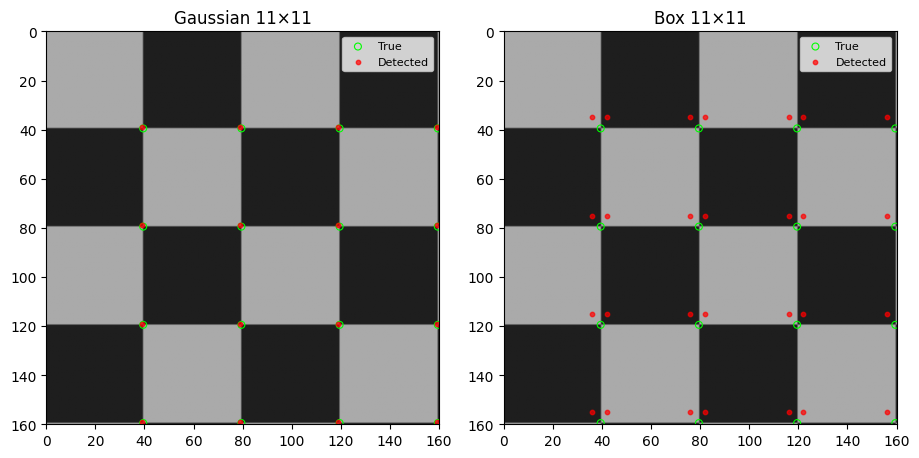

In [21]:
# Box-vs-Gaussian: exact same 11x11 support, same gradients, threshold and NMS.
WINDOWS=[]
for key in ('checkerboard',)+PHOTOS:
    for win in ('gaussian','box'):
        r=response_map(IMAGES[key],window=win)
        pts=points_from_response(r,border=6)
        row=dict(image=key,window=win,count=len(pts))
        if key=='checkerboard':
            distances=np.hypot(GT[:,None,0]-pts[None,:,0],GT[:,None,1]-pts[None,:,1])
            row.update(truth_found_2px=int(np.sum(distances.min(axis=1)<=2)),
                       mean_truth_error_px=float(distances.min(axis=1).mean()))
        WINDOWS.append(row)
print('Equal-size Gaussian and box window (11×11):')
for item in WINDOWS:print(item)
save_rows(OUT/'task5_comparison'/'windows.csv',WINDOWS)
fig,axes=plt.subplots(1,2,figsize=(9.3,4.5))
for ax,win in zip(axes,('gaussian','box')):
    ax.imshow(IMAGES['checkerboard'],cmap='gray',vmin=0,vmax=255)
    pts=points_from_response(response_map(IMAGES['checkerboard'],window=win))
    ax.scatter(GT[:,0],GT[:,1],s=25,facecolors='none',edgecolors='lime',lw=.8,label='True')
    ax.scatter(pts[:,0],pts[:,1],s=10,c='red',alpha=.7,label='Detected')
    ax.set(title=win.capitalize()+' 11×11',xlim=(0,160),ylim=(160,0));ax.legend(fontsize=8)
finish_figure(fig,'task5_comparison','checkerboard_window_localization.png')

In [22]:
# Task 5 REFERENCE ONLY: forbidden cv2.cornerHarris is isolated in this comparison function.
def opencv_reference_response(image,k=.04,block_size=11):
    return cv2.cornerHarris(np.asarray(image,dtype=np.float32),block_size,3,k,
                           borderType=cv2.BORDER_REFLECT_101).astype(np.float64)

def directed_agreement(P,Q,shape,tol=2):
    mask=np.zeros(shape,dtype=bool)
    if len(Q):mask[Q[:,1].astype(int),Q[:,0].astype(int)]=True
    score,n,_=repeatability(P,np.ones(shape,dtype=bool),mask,tol)
    return score

COMPARISONS=[]
for key in PHOTOS+('checkerboard',):
    img=IMAGES[key]
    rv=opencv_reference_response(img)
    cv_points=points_from_response(rv)
    for name in ('gaussian','box'):
        rc=response_map(img,window=name)
        ours=points_from_response(rc)
        COMPARISONS.append(dict(image=key,custom=name,custom_corners=len(ours),opencv_corners=len(cv_points),
            custom_to_opencv_pct=round(100*directed_agreement(ours,cv_points,img.shape),2),
            opencv_to_custom_pct=round(100*directed_agreement(cv_points,ours,img.shape),2)))
    # If gradients, border, box size and normalizing factors match, R is ~16 times box response.
    rbox=response_map(img,window='box')
    rel_error=np.max(np.abs(rv-16*rbox))/max(float(np.max(np.abs(rv))),1.)
    print(key,'OpenCV response vs 16× custom box relative error:',round(float(rel_error),7))
print('Directed match within <=2px, in percent (both use same 1% relative threshold and NMS):')
for row in COMPARISONS:print(row)
save_rows(OUT/'task5_comparison'/'opencv_agreement.csv',COMPARISONS)

structured OpenCV response vs 16× custom box relative error: 3e-07
natural OpenCV response vs 16× custom box relative error: 3e-07
low_contrast OpenCV response vs 16× custom box relative error: 3e-07
checkerboard OpenCV response vs 16× custom box relative error: 0.0
Directed match within <=2px, in percent (both use same 1% relative threshold and NMS):
{'image': 'structured', 'custom': 'gaussian', 'custom_corners': 165, 'opencv_corners': 292, 'custom_to_opencv_pct': 24.85, 'opencv_to_custom_pct': 14.04}
{'image': 'structured', 'custom': 'box', 'custom_corners': 292, 'opencv_corners': 292, 'custom_to_opencv_pct': 100.0, 'opencv_to_custom_pct': 100.0}
{'image': 'natural', 'custom': 'gaussian', 'custom_corners': 852, 'opencv_corners': 1407, 'custom_to_opencv_pct': 21.6, 'opencv_to_custom_pct': 14.85}
{'image': 'natural', 'custom': 'box', 'custom_corners': 1407, 'opencv_corners': 1407, 'custom_to_opencv_pct': 100.0, 'opencv_to_custom_pct': 100.0}
{'image': 'low_contrast', 'custom': 'gaussia

In [23]:
# Fair timed comparison: response-map only AND response+shared postprocessing.
TIMING=[]
for key in PHOTOS:
    img=IMAGES[key]
    def run_custom():return response_map(img,window='gaussian')
    def run_cv():return opencv_reference_response(img)
    def full_custom():return points_from_response(run_custom())
    def full_cv():return points_from_response(run_cv())
    TIMING.append(dict(image=key,
        custom_response_ms=round(run_ms(run_custom,7),3),opencv_response_ms=round(run_ms(run_cv,7),3),
        custom_full_ms=round(run_ms(full_custom,7),3),opencv_full_ms=round(run_ms(full_cv,7),3)))
print('Median 7 runs, machine-dependent wall time (ms):')
for t in TIMING:print(t)
save_rows(OUT/'task5_comparison'/'runtime.csv',TIMING)

Median 7 runs, machine-dependent wall time (ms):
{'image': 'structured', 'custom_response_ms': 3.647, 'opencv_response_ms': 0.302, 'custom_full_ms': 10.519, 'opencv_full_ms': 7.0}
{'image': 'natural', 'custom_response_ms': 3.877, 'opencv_response_ms': 0.292, 'custom_full_ms': 10.364, 'opencv_full_ms': 7.207}
{'image': 'low_contrast', 'custom_response_ms': 3.423, 'opencv_response_ms': 0.271, 'custom_full_ms': 10.931, 'opencv_full_ms': 6.891}


**Comparison interpretation.** Window shape changes the spatial weights in \(M\) and can move, merge, or split response maxima. OpenCV uses a **box** aggregation window; the reference response and the custom box response should agree up to library-specific normalization and `float32` rounding. Directed matching is reported **in both directions** to reveal extra detections, rather than claiming equal precision from one score. Timings compare identical image sizes and include an explicitly separated postprocessing cost. The checkerboard permits a measured localization error, while natural-image corner counts alone cannot prove correctness.

## Reproducibility and implementation audit

In [24]:
# End-to-end guardrail checks: no forbidden OpenCV filter call outside Task 1
# verification or cornerHarris outside Task 5 reference; only kernel taps / parameter
# sweeps / small offset neighborhoods use Python loops, never a per-image-pixel loop.
assert set(IMAGES)=={'checkerboard','structured','natural','low_contrast'}
assert all(v.ndim==2 and np.issubdtype(v.dtype,np.integer) for v in IMAGES.values())
assert len(GRID)==360 and len(RESULTS)==3*sum(map(len,VALUES.values()))
assert all(0<=r['relative']<=1 for r in RESULTS if np.isfinite(r['relative']))
assert len(WINDOWS)==8 and len(COMPARISONS)==8
assert len(bench)==5
summary={'python':platform.python_version(),'numpy':np.__version__,'opencv':cv2.__version__,
         'seed':SEED,'scikit_image':skimage_version,'images':{key:list(im.shape) for key,im in IMAGES.items()},
         'image_sources':IMAGE_SOURCES,
         'settings':{'sigma':SIGMA,'k':K,'rel_threshold':REL_THR,'padding':PADDING,'gradient':GRADIENT},
         'checkerboard_true_corners':len(GT),'checkerboard_detected':len(DETECTIONS['checkerboard']['corners']),
         'n_invariance_settings':len(RESULTS),'n_grid_settings':len(GRID)}
(OUT/'experiment_summary.json').write_text(json.dumps(summary,indent=2))
print('All required sections executed; dataset, checkerboard, identities, transformations, grid and comparisons validated.')
print('CSV and figure outputs are reproducibly regenerated in:',OUT)

All required sections executed; dataset, checkerboard, identities, transformations, grid and comparisons validated.
CSV and figure outputs are reproducibly regenerated in: /mnt/data/cv_fix_work/results


**Execution notes and provenance.** Requires Python 3.10+ with `numpy`, `matplotlib`, `opencv-python`, `scikit-image`, and `ipykernel`/Jupyter (or `nbclient` for batch execution). All three photos are loaded from the local `skimage.data` samples (`brick`, `grass`, and `coffee`); the `coffee` image is deliberately contrast-compressed to create the low-contrast experiment. The fourth image is the synthetic checkerboard matching the supplied notebooks. Images are not downloaded and their pixel arrays are not embedded as encoded text. The source imagery is used for testing only; image-specific reuse/licensing requirements should be checked against the scikit-image dataset documentation for redistribution. A fixed seed controls noise and scatter sampling; benchmark times vary by machine. OpenCV filtering occurs **only** in Task 1 verification, and `cv2.cornerHarris` occurs **only** in Task 5 comparison. All filtering, gradients, tensors, response maps, and non-maximum suppression in the custom detector are implemented with NumPy. The instructor's final report has not been generated: Phase 2 (three-page report, README, requirements, and ZIP) remains locked pending approval of this notebook.
